# Before you start :
   - These exercises are related to the Pivot table and correlation lessons.
   - Keep in mind that you need to use some of the functions you learned in the previous lessons.
   - All datasets are provided in the `your-code` folder of this lab.
   - Elaborate your codes and outputs as much as you can.
   - Try your best to answer the questions and complete the tasks and most importantly enjoy the process!!!

#### Import all the libraries that are necessary

In [1]:
# import libraries here
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

def describe_r(r):
    """Words for the strength and direction of a correlation coefficient."""
    strength = "very strong" if abs(r) >= .8 else "strong" if abs(r) >= .6 else "moderate" if abs(r) >= .4 else "weak" if abs(r) >= .2 else "very weak / no"
    return f"{strength} {'positive' if r > 0 else 'negative'} linear relationship (r = {r:.2f})"

# Challenge 1

#### Open the ` Employee.csv` file and name your dataset `employee`

In [2]:
employee = pd.read_csv("data/Employee.csv")
employee

,Name,Department,Education,Gender,Title,Years,Salary
0,Jose,IT,Bachelor,M,analyst,1,35
1,Maria,IT,Master,F,analyst,2,30
2,David,HR,Master,M,analyst,2,30
3,Sonia,HR,Bachelor,F,analyst,4,35
4,Samuel,Sales,Master,M,associate,3,55
5,Eva,Sales,Bachelor,F,associate,2,55
6,Carlos,IT,Master,M,VP,8,70
7,Pedro,IT,Phd,M,associate,7,60
8,Ana,HR,Master,F,VP,8,70


#### What's the mean salary by department. 
##### Tip : There are 2 ways to do it - one way is with and the other way is without pivot tables. Do it both ways. 


In [3]:
# 1st way: groupby
employee.groupby("Department")["Salary"].mean()

Department
HR       45.00
IT       48.75
Sales    55.00
Name: Salary, dtype: float64

In [4]:
# 2nd way: pivot table
pd.pivot_table(employee, index="Department", values="Salary", aggfunc="mean")

,Salary
Department,
HR,45.00
IT,48.75
Sales,55.00


#### We want now to group the data by more than one column. Use Pandas pivot table function to select the mean salary by department and title

In [5]:
pd.pivot_table(employee, index=["Department", "Title"], values="Salary", aggfunc="mean")

Salary
Department Title            
HR         VP           70.0
           analyst      32.5
IT         VP           70.0
           analyst      32.5
           associate    60.0
Sales      associate    55.0

#### We want to display the number of years of work experience and the salary for each Title. Add Years as a column in your pivot table
*Hint: Use Pandas doc(see References in README.md) to explore the pivot_table() arguments*

In [6]:
pd.pivot_table(employee, index=["Department", "Title"], values=["Salary", "Years"], aggfunc="mean")

Salary  Years
Department Title                   
HR         VP           70.0    8.0
           analyst      32.5    3.0
IT         VP           70.0    8.0
           analyst      32.5    1.5
           associate    60.0    7.0
Sales      associate    55.0    2.5

#### We want to know the information about the mean salary and number of employees in each department and for each job title

In [7]:
pd.pivot_table(employee, index=["Department", "Title"], values="Salary", aggfunc=["mean", "count"])

mean  count
                     Salary Salary
Department Title                  
HR         VP          70.0      1
           analyst     32.5      2
IT         VP          70.0      1
           analyst     32.5      2
           associate   60.0      1
Sales      associate   55.0      2

#### We want to know for each department and for each job title the Salary's median,minimum,maximum and standard deviation. Comment your results

In [8]:
stats_table = pd.pivot_table(employee, index=["Department", "Title"], values="Salary",
                             aggfunc=["median", "min", "max", "std"])
display(stats_table)
# Comment: the standard deviation is NaN for groups with only one employee (the standard deviation of a single value
# is undefined). For those groups median, min and max are the same value.

median    min    max       std
                     Salary Salary Salary    Salary
Department Title                                   
HR         VP          70.0     70     70       NaN
           analyst     32.5     30     35  3.535534
IT         VP          70.0     70     70       NaN
           analyst     32.5     30     35  3.535534
           associate   60.0     60     60       NaN
Sales      associate   55.0     55     55  0.000000

#### Based on your comments, fill the missing values with an appropriate value

In [9]:
# NaN standard deviations come from groups of one person, i.e. there is no variation: fill them with 0.
stats_table = stats_table.fillna(0)
stats_table

median    min    max       std
                     Salary Salary Salary    Salary
Department Title                                   
HR         VP          70.0     70     70  0.000000
           analyst     32.5     30     35  3.535534
IT         VP          70.0     70     70  0.000000
           analyst     32.5     30     35  3.535534
           associate   60.0     60     60  0.000000
Sales      associate   55.0     55     55  0.000000

#### The stake holders want to know for each department the number of employees and how much money is spend on salaries. Could you provide that information? 

In [10]:
pd.pivot_table(employee, index="Department", values="Salary", aggfunc={"Salary": "sum"}).join(
    employee.groupby("Department")["Name"].count().rename("employees"))

,Salary,employees
Department,,
HR,135,3
IT,195,4
Sales,110,2


#### For each Department and Title, we want to know the the total years of work experience and the mean salary

In [11]:
pd.pivot_table(employee, index=["Department", "Title"], values=["Years", "Salary"],
               aggfunc={"Years": "sum", "Salary": "mean"})

Salary  Years
Department Title                   
HR         VP           70.0      8
           analyst      32.5      6
IT         VP           70.0      8
           analyst      32.5      3
           associate    60.0      7
Sales      associate    55.0      5

#### Bonus

#### We now want to compute the mean salary after removing the maxima for each Department. Create the appropriate pivot table

#### * Hint: Write a custom function*

In [12]:
# Custom function: mean after removing the maximum value of the group
def mean_without_max(x):
    return x.drop(x.idxmax()).mean() if len(x) > 1 else np.nan

In [13]:
pd.pivot_table(employee, index="Department", values="Salary", aggfunc=mean_without_max)

,Salary
Department,
HR,32.500000
IT,41.666667
Sales,55.000000


# Challenge 2

#### Open the ` Fitbit.csv` file and name your dataset `fitbit`

In [14]:
fitbit = pd.read_csv("data/Fitbit.csv")
fitbit.head()

,Date,Calorie burned,Steps,Distance,Floors,Minutes Sedentary,Minutes Lightly Active,Minutes Fairly Active,Minutes Very Active,Activity Calories,MinutesOfSleep,MinutesOfBeingAwake,NumberOfAwakings,LengthOfRestInMinutes
0,08-05-2015,1934,905,0.65,0,1.355,46,0,0,1680,384,26,23,417
1,09-05-2015,3631,18925,14.11,4,611.000,316,61,60,2248,454,35,21,491
2,10-05-2015,3204,14228,10.57,1,602.000,226,14,77,1719,387,46,25,436
3,11-05-2015,2673,6756,5.02,8,749.000,190,23,4,9620,311,31,21,350
4,12-05-2015,2495,502,3.73,1,876.000,171,0,0,7360,407,65,44,491


#### Explore you dataset in terms of data types and descriptive statistics
#### *Hint: Use Pandas functions from previous lectures*

In [15]:
fitbit.dtypes

Date                          str
Calorie burned              int64
Steps                       int64
Distance                  float64
Floors                      int64
Minutes Sedentary         float64
Minutes Lightly Active      int64
Minutes Fairly Active       int64
Minutes Very Active         int64
Activity Calories           int64
MinutesOfSleep              int64
MinutesOfBeingAwake         int64
NumberOfAwakings            int64
LengthOfRestInMinutes       int64
dtype: object

In [16]:
fitbit.describe().T

,count,mean,std,min,25%,50%,75%,max
Calorie burned,367.0,2741.501362,916.307036,179.000,2698.000,2974.00,3233.00,4351.00
Steps,367.0,10121.588556,5594.836225,0.000,6730.500,10413.00,13916.50,26444.00
Distance,367.0,8.549128,3.409881,0.000,6.155,8.29,10.56,20.45
Floors,367.0,11.724796,10.337370,0.000,5.000,11.00,16.00,101.00
Minutes Sedentary,367.0,563.934482,294.793145,1.002,520.000,663.00,756.50,998.00
Minutes Lightly Active,367.0,236.405995,86.531376,0.000,179.000,226.00,290.00,472.00
Minutes Fairly Active,367.0,26.163488,20.319456,0.000,8.000,24.00,41.50,101.00
Minutes Very Active,367.0,35.722071,31.006682,0.000,10.500,29.00,54.00,153.00
Activity Calories,367.0,2044.147139,2041.267168,0.000,1218.500,1553.00,1927.50,9830.00
MinutesOfSleep,367.0,290.479564,154.752328,0.000,224.000,337.00,400.50,553.00


#### You suspect that there must be a linear relationship between the Minutes Very Active and the Steps. Compute the correlation between these variables.

In [17]:
r1 = fitbit["Minutes Very Active"].corr(fitbit["Steps"])
print(f"Correlation Minutes Very Active vs. Steps: {r1:.3f}")

Correlation Minutes Very Active vs. Steps: 0.571


#### Use matplotlib to visually plot Minutes Very active vs Steps. 

##### Hint : import matplotlib.pyplot as plt (See previous lessons)#####
- Use plt.scatter(x=df['col_name_1'], y=df['col_name_2'])

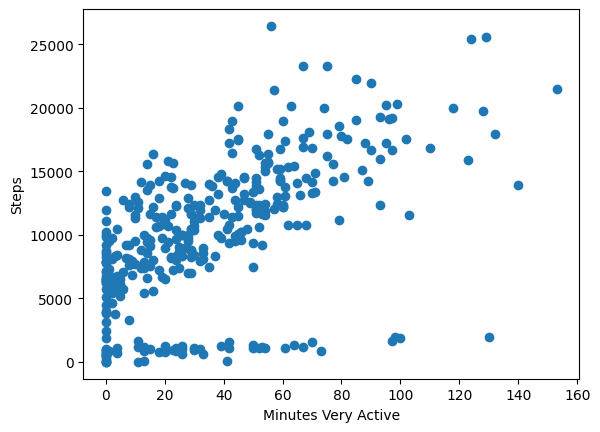

In [18]:
plt.scatter(x=fitbit["Minutes Very Active"], y=fitbit["Steps"])
plt.xlabel("Minutes Very Active"); plt.ylabel("Steps")
plt.show()

#### What can you say about Minute Very Active and Steps? Write a comment below

In [19]:
# Comment:
print("Minutes Very Active and Steps have a", describe_r(r1))
# The more minutes a person is very active, the more steps they take, which is logical.

Minutes Very Active and Steps have a moderate positive linear relationship (r = 0.57)


#### We also suspect that there must be a linear relationship between the Minutes Sedentary and the Steps. Compute the correlation between these variables.

In [20]:
r2 = fitbit["Minutes Sedentary"].corr(fitbit["Steps"])
print(f"Correlation Minutes Sedentary vs. Steps: {r2:.3f}")

Correlation Minutes Sedentary vs. Steps: 0.077


#### Use matplotlib to visually plot Minutes Sedentary vs Steps. Based on the results of the computed correlation and the plot. What can you say about these 2 variables?

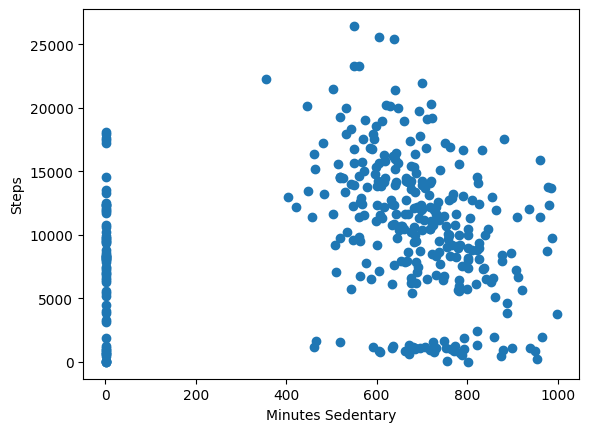

In [21]:
plt.scatter(x=fitbit["Minutes Sedentary"], y=fitbit["Steps"])
plt.xlabel("Minutes Sedentary"); plt.ylabel("Steps")
plt.show()

In [22]:
# Comment:
print("Minutes Sedentary and Steps have a", describe_r(r2))
# The relationship is weak: the sedentary minutes do not say much about the steps in this dataset.

Minutes Sedentary and Steps have a very weak / no positive linear relationship (r = 0.08)


#### We also suspect that there must be a linear relationship between the MinutesOfSleep and the Steps. Compute the correlation between these variables.

In [23]:
r3 = fitbit["MinutesOfSleep"].corr(fitbit["Steps"])
print(f"Correlation MinutesOfSleep vs. Steps: {r3:.3f}")

Correlation MinutesOfSleep vs. Steps: 0.131


#### Use matplotlib to visually plot MinutesOfSleep vs Steps. Based on the results of the computed correlation and the plot. What can you say about these 2 variables?

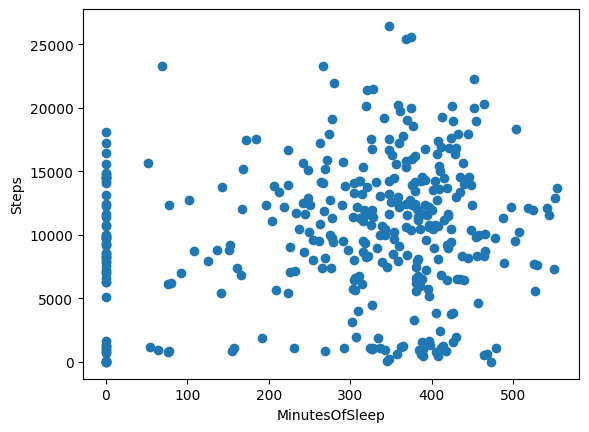

MinutesOfSleep and Steps have a very weak / no positive linear relationship (r = 0.13)


In [24]:
plt.scatter(x=fitbit["MinutesOfSleep"], y=fitbit["Steps"])
plt.xlabel("MinutesOfSleep"); plt.ylabel("Steps")
plt.show()
print("MinutesOfSleep and Steps have a", describe_r(r3))
# Sleep time is not a useful predictor of the number of steps.

#### Select a subset of your dataset with the columns below and compute the correlation matrix. Save the results in the variable `cor_fit`
column= ['Calorie burned', 'Steps','Floors','Minutes Sedentary','Minutes Very Active', 'MinutesOfSleep']

In [25]:
column = ['Calorie burned', 'Steps', 'Floors', 'Minutes Sedentary', 'Minutes Very Active', 'MinutesOfSleep']
cor_fit = fitbit[column].corr()

In [26]:
#Print cor_fit
cor_fit.round(2)

,Calorie burned,Steps,Floors,Minutes Sedentary,Minutes Very Active,MinutesOfSleep
Calorie burned,1.00,0.26,0.13,0.13,0.20,0.01
Steps,0.26,1.00,0.31,0.08,0.57,0.13
Floors,0.13,0.31,1.00,0.06,0.40,0.07
Minutes Sedentary,0.13,0.08,0.06,1.00,0.11,0.20
Minutes Very Active,0.20,0.57,0.40,0.11,1.00,0.11
MinutesOfSleep,0.01,0.13,0.07,0.20,0.11,1.00


#### Based on the result of the correlation matrix. What are the highly correlated features with the variable Steps?
*Hint: From the results above select the variable Steps and order your results in descending order (use Pandas sort_values function)*

In [27]:
cor_fit["Steps"].drop("Steps").sort_values(ascending=False)
# Minutes Very Active is the only feature with a clear correlation with Steps (about 0.57); Floors (about 0.31) and
# Calorie burned (about 0.26) are only weakly correlated, sleep and sedentary minutes hardly at all.

Minutes Very Active    0.571452
Floors                 0.306511
Calorie burned         0.255305
MinutesOfSleep         0.130986
Minutes Sedentary      0.076906
Name: Steps, dtype: float64

# Challenge 3

#### Open the `Time_Grades.csv` file and name your dataset `time_grades`

In [28]:
time_grades = pd.read_csv("data/Time_Grades.csv")

In [29]:
#Print time_grades
time_grades

,Name,Study time,Grade
0,Jose,4,4
1,Maria,9,7
2,David,8,9
3,Sonia,10,7
4,Samuel,20,9
5,Eva,5,3
6,Carlos,12,7
7,Pedro,6,5
8,Ana,18,9
9,Gervasio,7,3


#### Show visually the frequency distribution of the time_grades dataset.

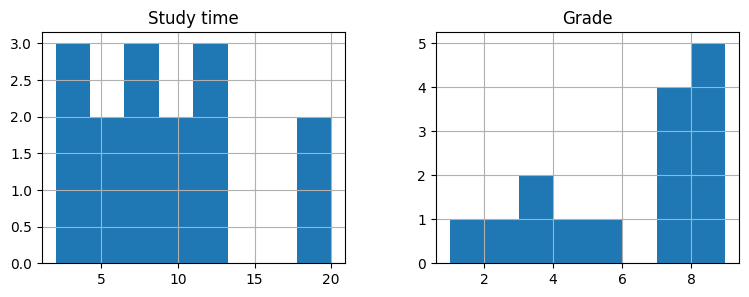

In [30]:
time_grades[["Study time", "Grade"]].hist(bins=8, figsize=(9, 3))
plt.show()

#### Is there a correaltion between study time and Grade? Use both Pearson and Spearman correlation and comment your results.

In [31]:
# Pearson correlation
pearson_r = time_grades["Study time"].corr(time_grades["Grade"], method="pearson")
print("Pearson:", round(pearson_r, 3), "->", describe_r(pearson_r))

Pearson: 0.798 -> strong positive linear relationship (r = 0.80)


In [32]:
## Spearman correlation
spearman_r = time_grades["Study time"].corr(time_grades["Grade"], method="spearman")
print("Spearman:", round(spearman_r, 3))
# Both coefficients are positive and high: students who study more get better grades.

Spearman: 0.82


#### Use matplotlib to visually plot Study time vs Grade. Based on the results of the computed correlation and the plot. What can you say about these 2 variables?

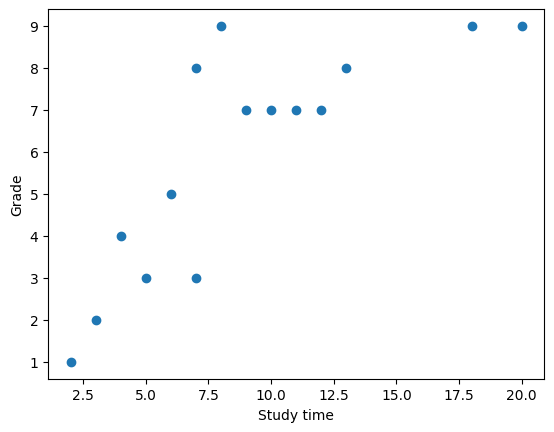

In [33]:
plt.scatter(x=time_grades["Study time"], y=time_grades["Grade"])
plt.xlabel("Study time"); plt.ylabel("Grade")
plt.show()

In [34]:
#your comment
# The scatter plot shows a clear upward trend, so more study time goes together with higher grades. This does not prove that
# study time causes the grades (motivation or prior knowledge can play a role), but the association is strong.

#### Could you explain the difference between Pearson and Spearman correlation? (see References in README.md) 

In [35]:
#your comment
# Pearson measures the strength of a LINEAR relationship between the values themselves and is sensitive to outliers.
# Spearman is the Pearson correlation of the RANKS, so it measures any monotonic relationship (always increasing or always
# decreasing, not necessarily a straight line) and is more robust against outliers and non-normal data.